In [1]:
# ============================================================
# UA-ProtoNet: N-Way K-Shot Sensitivity Study & Robustness Analysis
# ============================================================

import csv
import os
import random
from collections import defaultdict
from dataclasses import dataclass
from contextlib import nullcontext

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import precision_score, recall_score, f1_score
from torchvision import datasets, models, transforms

# ------------------------------------------------------------
# 1. Configurable Paths & Parameters
# ------------------------------------------------------------
PLANTVILLAGE_ROOT = "/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color"
WEIGHTS_PATH      = "/kaggle/input/models/tanvirakon/main2/pytorch/default/1/opus.pth"
OUTPUT_DIR        = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."

DEVICE            = "cuda" if torch.cuda.is_available() else "cpu"
IMAGE_SIZE        = 224
SPLIT_SEED        = 42

DRY_RUN = False  # Full 300-episode benchmark evaluation

# ------------------------------------------------------------
# 2. Checkpoint & Dataset Finders
# ------------------------------------------------------------
def find_dataset_root(preferred, dataset_token, leaf_name):
    if os.path.isdir(preferred):
        return preferred
    candidates = []
    for search_root in ("/kaggle/input", "."):
        if not os.path.isdir(search_root):
            continue
        for root, _, _ in os.walk(search_root):
            if os.path.basename(root).lower() == leaf_name.lower() and dataset_token in root.lower():
                candidates.append(root)
    if not candidates:
        raise FileNotFoundError(f"Could not find {dataset_token} dataset directory.")
    return sorted(candidates)[0]


def find_weights():
    if os.path.isfile(WEIGHTS_PATH):
        return WEIGHTS_PATH
    candidates = []
    for search_root in ("/kaggle/input", "/kaggle/working", "."):
        if not os.path.isdir(search_root):
            continue
        for root, _, files in os.walk(search_root):
            candidates.extend(os.path.join(root, f) for f in files if f.lower().endswith((".pth", ".pt")))
    candidates = sorted(set(candidates))
    if len(candidates) == 1:
        return candidates[0]
    if not candidates:
        raise FileNotFoundError("No .pth or .pt checkpoint file found.")
    raise RuntimeError(
        "Multiple checkpoints found. Please specify WEIGHTS_PATH explicitly:\n  "
        + "\n  ".join(candidates)
    )


def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(SPLIT_SEED)

def autocast_context():
    if DEVICE == "cuda":
        return torch.amp.autocast("cuda")
    return nullcontext()

# ------------------------------------------------------------
# 3. Model Architecture (Matching opus.pth exactly)
# ------------------------------------------------------------
class ChannelAttention(nn.Module):
    def __init__(self, in_planes, reduction=16):
        super().__init__()
        reduced = max(1, in_planes // reduction)
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.fc = nn.Sequential(
            nn.Conv2d(in_planes, reduced, 1, bias=False),
            nn.ReLU(),
            nn.Conv2d(reduced, in_planes, 1, bias=False)
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        mask = self.sigmoid(self.fc(self.avg_pool(x)) + self.fc(self.max_pool(x)))
        return x * mask


class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv1 = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        mask = self.sigmoid(self.conv1(torch.cat([avg_out, max_out], dim=1)))
        return x * mask


class DualAttention(nn.Module):
    def __init__(self, in_planes, reduction=16, kernel_size=7):
        super().__init__()
        self.ca = ChannelAttention(in_planes, reduction)
        self.sa = SpatialAttention(kernel_size)

    def forward(self, x):
        return self.sa(self.ca(x))


class EfficientNetB0FSL(nn.Module):
    def __init__(self):
        super().__init__()
        effnet = models.efficientnet_b0(weights=None)
        self.features_early = effnet.features[:7]
        self.attention_mid = DualAttention(192, reduction=8)
        self.features_late = effnet.features[7:]
        self.attention_final = DualAttention(1280, reduction=16)
        self.pooling = nn.AdaptiveAvgPool2d(1)
        self.mid_proj = nn.Linear(192, 128)
        self.late_proj = nn.Linear(1280, 128)
        self.mcd_dropout = nn.Dropout(p=0.5)
        self.proj = nn.Linear(256, 256)
        self.temperature = nn.Parameter(torch.tensor(1.0))

    def forward(self, x, apply_mcd=False):
        x_mid = self.attention_mid(self.features_early(x))
        x_late = self.attention_final(self.features_late(x_mid))
        mid_feat = self.mid_proj(torch.flatten(self.pooling(x_mid), 1))
        late_feat = self.late_proj(torch.flatten(self.pooling(x_late), 1))
        combined = torch.cat([mid_feat, late_feat], dim=1)
        if apply_mcd:
            combined = F.dropout(combined, p=0.5, training=True)
        else:
            combined = self.mcd_dropout(combined)
        return F.normalize(self.proj(combined), dim=1)


def compute_prototypes(embeddings, labels, n_way):
    return torch.stack([embeddings[labels == c].mean(dim=0) for c in range(n_way)])


def euclidean_logits(query_embeddings, prototypes, temperature=1.0):
    return -torch.cdist(query_embeddings, prototypes, p=2) / temperature

# ------------------------------------------------------------
# 4. Evaluation Configuration & Helpers
# ------------------------------------------------------------
@dataclass
class EvalConfig:
    data_root:     str   = PLANTVILLAGE_ROOT
    weights_path:  str   = WEIGHTS_PATH
    image_size:    int   = IMAGE_SIZE
    device:        str   = DEVICE
    seed:          int   = SPLIT_SEED
    q_query:       int   = 2 if DRY_RUN else 15
    eval_episodes: int   = 2 if DRY_RUN else 300
    mcd_passes:    int   = 10
    n_way_list:    tuple = (3, 5, 7)  # Clamped to 7 (max test classes in PV test split)
    k_shot_list:   tuple = (1, 5, 10)

ECFG = EvalConfig()

def build_class_to_indices(ds):
    class_to_indices = defaultdict(list)
    for idx, target in enumerate(ds.targets):
        class_to_indices[target].append(idx)
    return dict(class_to_indices)

# ------------------------------------------------------------
# 5. Master 7-Way Episode Generator (Hierarchically Paired Data Sets)
# ------------------------------------------------------------
def generate_master_7way_episodes(test_classes, class_to_indices, max_k_shot, q_query, num_episodes, seed):
    """
    Generates a master 7-way episode set.
    For N-way (3, 5, 7), the first N classes are taken.
    For K-shot (1, 5, 10), the first K support images per class are taken.
    This guarantees 100% paired, nested data hierarchy across all (N, K) settings.
    """
    rng = random.Random(seed)
    master_episodes = []

    for ep_id in range(num_episodes):
        sampled_classes = rng.sample(test_classes, 7)
        support_indices_by_class = {}
        query_indices_by_class = {}

        for cls in sampled_classes:
            available = class_to_indices[cls]
            selected = rng.sample(available, max_k_shot + q_query)
            support_indices_by_class[cls] = selected[:max_k_shot]
            query_indices_by_class[cls]   = selected[max_k_shot:]

        master_episodes.append({
            "episode_id": ep_id,
            "master_classes": sampled_classes,
            "support_indices_by_class": support_indices_by_class,
            "query_indices_by_class": query_indices_by_class
        })

    return master_episodes

# ------------------------------------------------------------
# 6. Optimized Fast Episode Evaluation with @torch.no_grad()
# ------------------------------------------------------------
@torch.no_grad()
def evaluate_episode_mcd_fast(model, base_dataset, episode, n_way, k_shot, mcd_passes, device):
    sampled_classes = episode["master_classes"][:n_way]
    
    support_x, support_y = [], []
    query_x, query_y, query_global_names = [], [], []

    for mapped_label, cls in enumerate(sampled_classes):
        for idx in episode["support_indices_by_class"][cls][:k_shot]:
            img, _ = base_dataset[idx]
            support_x.append(img)
            support_y.append(mapped_label)

        for idx in episode["query_indices_by_class"][cls]:
            img, _ = base_dataset[idx]
            query_x.append(img)
            query_y.append(mapped_label)
            query_global_names.append(base_dataset.classes[cls])

    support_x = torch.stack(support_x).to(device)
    support_y = torch.tensor(support_y, dtype=torch.long).to(device)
    query_x   = torch.stack(query_x).to(device)
    query_y   = torch.tensor(query_y, dtype=torch.long).to(device)

    n_support = support_x.size(0)
    all_x = torch.cat([support_x, query_x], dim=0)

    model.eval()

    probs_list = []
    per_pass_entropies = []
    
    base_mcd_seed = 9999 + episode["episode_id"] * 100

    for pass_idx in range(mcd_passes):
        torch.manual_seed(base_mcd_seed + pass_idx)

        with autocast_context():
            all_embeddings = model(all_x, apply_mcd=True)
            supp_emb  = all_embeddings[:n_support]
            query_emb = all_embeddings[n_support:]

            protos = compute_prototypes(supp_emb, support_y, n_way)
            logits = euclidean_logits(query_emb, protos, model.temperature)
            probs  = F.softmax(logits, dim=1)

        probs_list.append(probs.float())

        eps = 1e-9
        h_pass = -torch.sum(probs.float() * torch.log(probs.float() + eps), dim=1)
        per_pass_entropies.append(h_pass)

    probs_stack = torch.stack(probs_list, dim=0)   # (T, N_queries, N_way)
    mean_probs  = probs_stack.mean(dim=0)          # (N_queries, N_way)
    preds_local = mean_probs.argmax(dim=1).cpu().numpy()

    acc = (preds_local == query_y.cpu().numpy()).mean()
    global_pred_names = [base_dataset.classes[sampled_classes[p]] for p in preds_local]

    eps = 1e-9
    predictive_entropy = -torch.sum(mean_probs * torch.log(mean_probs + eps), dim=1).mean().item()
    
    max_entropy = np.log(n_way)
    norm_predictive_entropy = predictive_entropy / max_entropy

    expected_entropy = torch.stack(per_pass_entropies, dim=0).mean(dim=0).mean().item()
    mutual_info = max(0.0, predictive_entropy - expected_entropy)
    norm_mutual_info = mutual_info / max_entropy

    return acc, global_pred_names, query_global_names, predictive_entropy, norm_predictive_entropy, mutual_info, norm_mutual_info

# ------------------------------------------------------------
# 7. Multi-Setting Evaluation Loop
# ------------------------------------------------------------
def run_all_evaluations(model, eval_ds, test_classes, class_to_indices, cfg):
    all_results = {}
    max_k_shot = max(cfg.k_shot_list)

    if DRY_RUN:
        print("⚠️ DRY RUN MODE ACTIVE: Running 2 episodes for quick verification...")
    else:
        print(f"🚀 FULL BENCHMARK MODE: Evaluating {cfg.eval_episodes} paired episodes per setting...")

    master_episodes = generate_master_7way_episodes(
        test_classes=test_classes,
        class_to_indices=class_to_indices,
        max_k_shot=max_k_shot,
        q_query=cfg.q_query,
        num_episodes=cfg.eval_episodes,
        seed=cfg.seed + 777
    )

    # Dynamic Student's t-critical value: 12.706 for 2 episodes (df=1), 1.968 for 300 episodes (df=299)
    if cfg.eval_episodes == 300:
        tcrit_95 = 1.968
    elif cfg.eval_episodes == 2:
        tcrit_95 = 12.706
    else:
        tcrit_95 = 1.96

    for n_way in cfg.n_way_list:
        for k_shot in cfg.k_shot_list:
            setting_key = f"{n_way}way_{k_shot}shot"
            print(f"\n--- Evaluating {n_way}-way {k_shot}-shot Sensitivity ---")

            episode_accs = []
            episode_entropies = []
            episode_norm_entropies = []
            episode_mis = []
            episode_norm_mis = []

            all_global_preds = []
            all_global_targets = []

            for ep in master_episodes:
                acc, preds_g, targets_g, h, norm_h, mi, norm_mi = evaluate_episode_mcd_fast(
                    model, eval_ds, ep, n_way, k_shot, cfg.mcd_passes, cfg.device
                )
                episode_accs.append(acc)
                episode_entropies.append(h)
                episode_norm_entropies.append(norm_h)
                episode_mis.append(mi)
                episode_norm_mis.append(norm_mi)

                all_global_preds.extend(preds_g)
                all_global_targets.extend(targets_g)

            mean_acc = float(np.mean(episode_accs))
            std_acc  = float(np.std(episode_accs, ddof=1)) if len(episode_accs) > 1 else 0.0
            ci95_acc = tcrit_95 * (std_acc / np.sqrt(len(episode_accs)))

            mean_norm_h = float(np.mean(episode_norm_entropies))
            std_norm_h  = float(np.std(episode_norm_entropies, ddof=1)) if len(episode_norm_entropies) > 1 else 0.0
            ci95_norm_h = tcrit_95 * (std_norm_h / np.sqrt(len(episode_norm_entropies)))

            mean_norm_mi = float(np.mean(episode_norm_mis))
            std_norm_mi  = float(np.std(episode_norm_mis, ddof=1)) if len(episode_norm_mis) > 1 else 0.0
            ci95_norm_mi = tcrit_95 * (std_norm_mi / np.sqrt(len(episode_norm_mis)))

            precision = float(precision_score(all_global_targets, all_global_preds, average='macro', zero_division=0))
            recall    = float(recall_score(all_global_targets, all_global_preds, average='macro', zero_division=0))
            f1        = float(f1_score(all_global_targets, all_global_preds, average='macro', zero_division=0))

            all_results[setting_key] = {
                'setting': setting_key,
                'n_way': n_way,
                'k_shot': k_shot,
                'mean_acc': mean_acc,
                'std_acc': std_acc,
                'ci95_acc': ci95_acc,
                'precision': precision,
                'recall': recall,
                'f1': f1,
                'mean_entropy': float(np.mean(episode_entropies)),
                'mean_norm_entropy': mean_norm_h,
                'ci95_norm_entropy': ci95_norm_h,
                'mean_mutual_info': float(np.mean(episode_mis)),
                'mean_norm_mutual_info': mean_norm_mi,
                'ci95_norm_mutual_info': ci95_norm_mi,
            }

            print(
                f"  => Acc: {mean_acc*100:.2f}% ± {ci95_acc*100:.2f}% (95% CI) | "
                f"P: {precision*100:.2f}% R: {recall*100:.2f}% F1: {f1*100:.2f}% | "
                f"Norm H: {mean_norm_h:.4f} ± {ci95_norm_h:.4f} | Norm MI: {mean_norm_mi:.4f} ± {ci95_norm_mi:.4f}"
            )

    return all_results

# ------------------------------------------------------------
# 8. Main Execution Flow
# ------------------------------------------------------------
if __name__ == "__main__":
    PLANTVILLAGE_ROOT = find_dataset_root(PLANTVILLAGE_ROOT, "plantvillage", "color")
    ckpt_path = find_weights()

    eval_tfms = transforms.Compose([
        transforms.Resize((ECFG.image_size, ECFG.image_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

    print(f"Loading PlantVillage dataset from: {PLANTVILLAGE_ROOT}")
    eval_ds = datasets.ImageFolder(PLANTVILLAGE_ROOT, transform=eval_tfms)
    eval_indices = build_class_to_indices(eval_ds)

    all_pv_classes = list(range(len(eval_ds.classes)))
    random.Random(SPLIT_SEED).shuffle(all_pv_classes)
    test_classes = all_pv_classes[31:38]  # 7 unseen test classes

    print(f"Test classes count: {len(test_classes)}")
    print(f"Loading checkpoint weights strictly from: {ckpt_path}")
    model = EfficientNetB0FSL().to(ECFG.device)
    try:
        state = torch.load(ckpt_path, map_location=ECFG.device, weights_only=True)
    except TypeError:
        state = torch.load(ckpt_path, map_location=ECFG.device)
    if isinstance(state, dict):
        for key in ("model_state_dict", "state_dict", "model"):
            if key in state and isinstance(state[key], dict):
                state = state[key]
                break
    clean_state = {k.replace("module.", ""): v for k, v in state.items()}
    model.load_state_dict(clean_state, strict=True)
    model.eval()
    print("Checkpoint loaded strictly and successfully.")

    # Run evaluations
    results = run_all_evaluations(model, eval_ds, test_classes, eval_indices, ECFG)

    # Save to CSV
    df = pd.DataFrame(list(results.values()))
    csv_path = os.path.join(OUTPUT_DIR, "n_way_k_shot_results.csv")
    df.to_csv(csv_path, index=False)
    print(f"\nSaved sensitivity evaluation metrics to: {csv_path}")

    globals()['results'] = results
    globals()['df'] = df


Loading PlantVillage dataset from: /kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color
Test classes count: 7
Loading checkpoint weights strictly from: /kaggle/input/models/tanvirakon/main2/pytorch/default/1/opus.pth
Checkpoint loaded strictly and successfully.
🚀 FULL BENCHMARK MODE: Evaluating 300 paired episodes per setting...

--- Evaluating 3-way 1-shot Sensitivity ---
  => Acc: 92.48% ± 0.95% (95% CI) | P: 92.70% R: 92.39% F1: 92.44% | Norm H: 0.5589 ± 0.0140 | Norm MI: 0.0117 ± 0.0004

--- Evaluating 3-way 5-shot Sensitivity ---
  => Acc: 97.16% ± 0.45% (95% CI) | P: 97.21% R: 97.11% F1: 97.15% | Norm H: 0.5035 ± 0.0141 | Norm MI: 0.0054 ± 0.0002

--- Evaluating 3-way 10-shot Sensitivity ---
  => Acc: 97.66% ± 0.41% (95% CI) | P: 97.70% R: 97.61% F1: 97.64% | Norm H: 0.4946 ± 0.0140 | Norm MI: 0.0045 ± 0.0001

--- Evaluating 5-way 1-shot Sensitivity ---
  => Acc: 85.98% ± 0.85% (95% CI) | P: 86.44% R: 85.96% F1: 85.93% | Norm H: 0.6385 ± 0.0057 | Norm MI: 0.0120 ± 0.0

Generating Publication-Grade Thesis Figures...
Saved Figure 1: /kaggle/working/fig_acc_vs_kshot.png


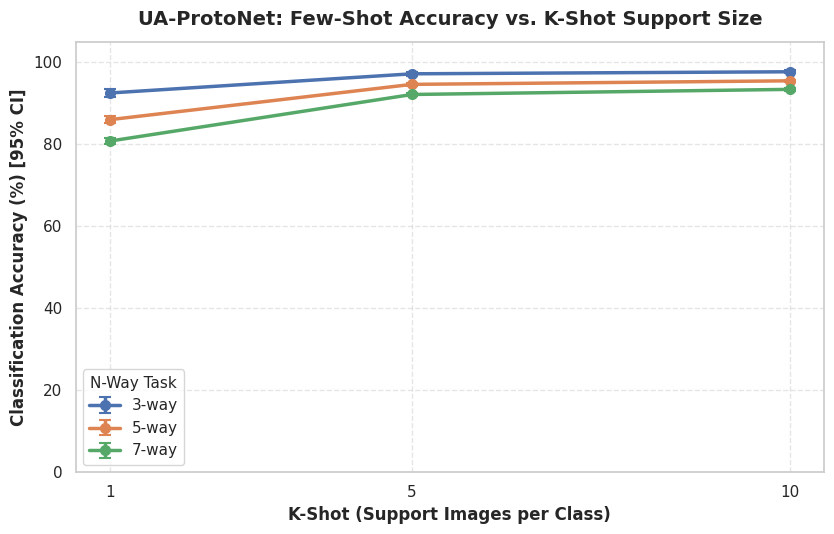

Saved Figure 2: /kaggle/working/fig_acc_vs_nway.png


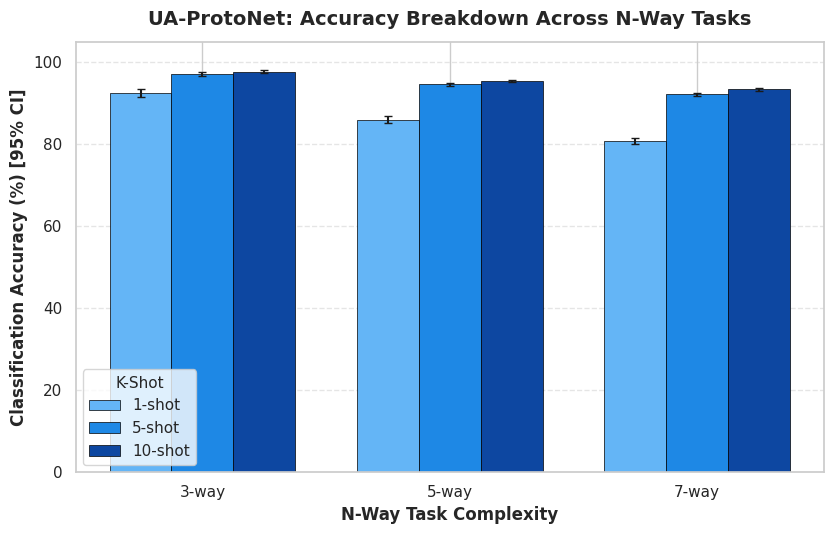

Saved Figure 3: /kaggle/working/fig_precision_recall_f1.png


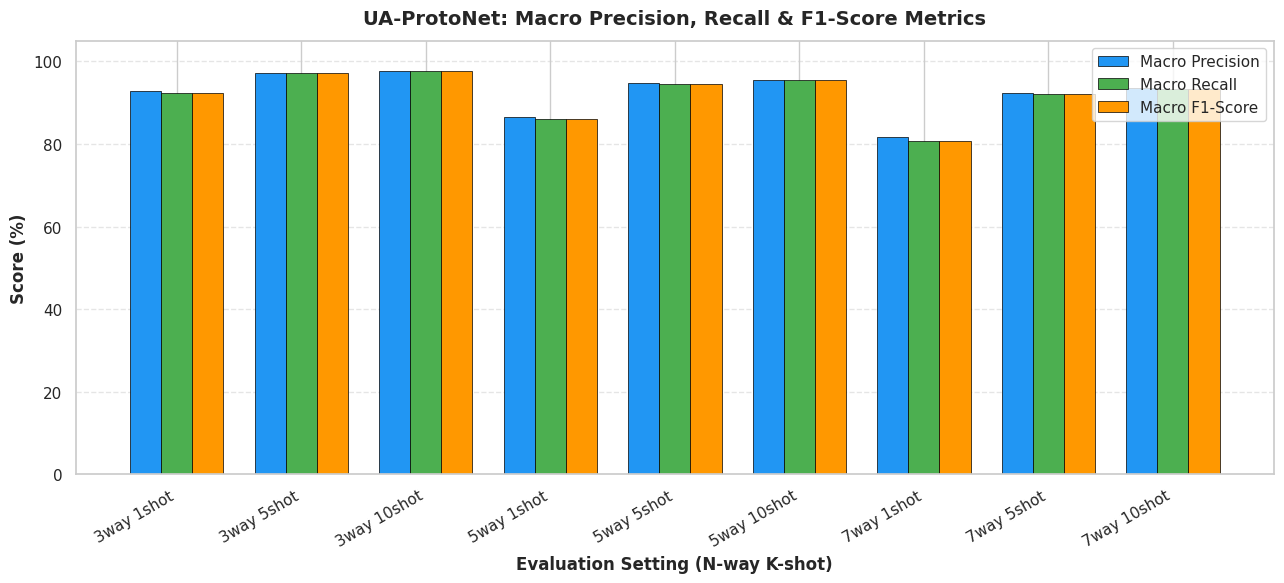

Saved Figure 4: /kaggle/working/fig_uncertainty_vs_kshot.png


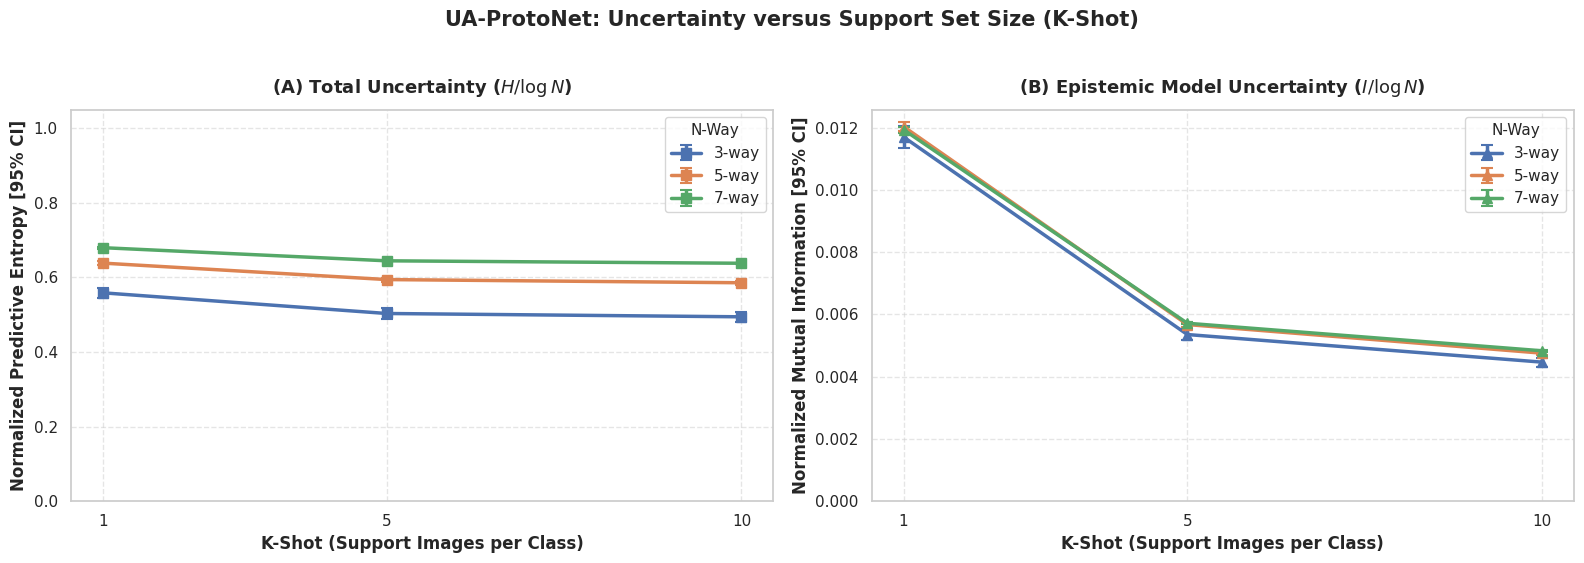

In [2]:
# ============================================================
# UA-ProtoNet: Publication-Grade N-Way K-Shot Sensitivity Figures
# ============================================================

import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

OUTPUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
CSV_PATH   = os.path.join(OUTPUT_DIR, "n_way_k_shot_results.csv")

# 1. Load Data strictly
if 'df' in globals() and isinstance(globals()['df'], pd.DataFrame):
    df = globals()['df']
elif os.path.isfile(CSV_PATH):
    print(f"Loading results from CSV: {CSV_PATH}")
    df = pd.read_csv(CSV_PATH)
else:
    raise FileNotFoundError(f"Could not find results dataframe or CSV at {CSV_PATH}. Please run 'n way nshot.py' first.")

required_cols = ['ci95_acc', 'ci95_norm_entropy', 'ci95_norm_mutual_info']
missing = [c for c in required_cols if c not in df.columns]
if missing:
    raise ValueError(f"CSV is missing required 95% CI columns: {missing}. Please re-run 'n way nshot.py'.")

sns.set_theme(style="whitegrid", font_scale=1.0)
n_ways = sorted(df['n_way'].unique())
k_shots = sorted(df['k_shot'].unique())

print("Generating Publication-Grade Thesis Figures...")

# ------------------------------------------------------------
# Figure 1: Accuracy vs. K-Shot with 95% Confidence Intervals
# ------------------------------------------------------------
fig1, ax1 = plt.subplots(figsize=(8.5, 5.5))
palette = sns.color_palette("deep", len(n_ways))

for idx, n_way in enumerate(n_ways):
    subset = df[df['n_way'] == n_way].sort_values('k_shot')
    ax1.errorbar(subset['k_shot'], subset['mean_acc'] * 100, yerr=subset['ci95_acc'] * 100,
                 marker='o', markersize=7, linewidth=2.5, capsize=4, capthick=1.5,
                 label=f'{n_way}-way', color=palette[idx])

ax1.set_xlabel('K-Shot (Support Images per Class)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Classification Accuracy (%) [95% CI]', fontsize=12, fontweight='bold')
ax1.set_title('UA-ProtoNet: Few-Shot Accuracy vs. K-Shot Support Size', fontsize=14, fontweight='bold', pad=12)
ax1.set_xticks(k_shots)
ax1.set_ylim(0, 105)
ax1.legend(fontsize=11, title="N-Way Task", title_fontsize=11)
ax1.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

fig1_path_png = os.path.join(OUTPUT_DIR, "fig_acc_vs_kshot.png")
fig1_path_pdf = os.path.join(OUTPUT_DIR, "fig_acc_vs_kshot.pdf")
fig1.savefig(fig1_path_png, dpi=300, bbox_inches="tight")
fig1.savefig(fig1_path_pdf, bbox_inches="tight")
print(f"Saved Figure 1: {fig1_path_png}")
plt.show()

# ------------------------------------------------------------
# Figure 2: Accuracy vs. N-Way with 95% Confidence Intervals
# ------------------------------------------------------------
fig2, ax2 = plt.subplots(figsize=(8.5, 5.5))
x = np.arange(len(n_ways))
width = 0.25
colors = ["#64B5F6", "#1E88E5", "#0D47A1"]

for i, k_shot in enumerate(k_shots):
    subset = df[df['k_shot'] == k_shot].sort_values('n_way')
    ax2.bar(x + i * width, subset['mean_acc'].values * 100, width, yerr=subset['ci95_acc'].values * 100, capsize=3,
            label=f'{k_shot}-shot', color=colors[i % len(colors)], edgecolor='black', linewidth=0.5)

ax2.set_xlabel('N-Way Task Complexity', fontsize=12, fontweight='bold')
ax2.set_ylabel('Classification Accuracy (%) [95% CI]', fontsize=12, fontweight='bold')
ax2.set_title('UA-ProtoNet: Accuracy Breakdown Across N-Way Tasks', fontsize=14, fontweight='bold', pad=12)
ax2.set_xticks(x + width)
ax2.set_xticklabels([f'{n}-way' for n in n_ways])
ax2.set_ylim(0, 105)
ax2.legend(fontsize=11, title="K-Shot", title_fontsize=11)
ax2.grid(True, linestyle="--", alpha=0.5, axis='y')
plt.tight_layout()

fig2_path_png = os.path.join(OUTPUT_DIR, "fig_acc_vs_nway.png")
fig2_path_pdf = os.path.join(OUTPUT_DIR, "fig_acc_vs_nway.pdf")
fig2.savefig(fig2_path_png, dpi=300, bbox_inches="tight")
fig2.savefig(fig2_path_pdf, bbox_inches="tight")
print(f"Saved Figure 2: {fig2_path_png}")
plt.show()

# ------------------------------------------------------------
# Figure 3: Precision, Recall & F1-Score Breakdown
# ------------------------------------------------------------
fig3, ax3 = plt.subplots(figsize=(13, 6))
settings = df['setting'].tolist()
precisions = df['precision'].values * 100
recalls    = df['recall'].values * 100
f1s        = df['f1'].values * 100

x = np.arange(len(settings))
width = 0.25

ax3.bar(x - width, precisions, width, label='Macro Precision', color='#2196F3', edgecolor='black', linewidth=0.5)
ax3.bar(x,         recalls,    width, label='Macro Recall',    color='#4CAF50', edgecolor='black', linewidth=0.5)
ax3.bar(x + width, f1s,        width, label='Macro F1-Score',  color='#FF9800', edgecolor='black', linewidth=0.5)

ax3.set_xlabel('Evaluation Setting (N-way K-shot)', fontsize=12, fontweight='bold')
ax3.set_ylabel('Score (%)', fontsize=12, fontweight='bold')
ax3.set_title('UA-ProtoNet: Macro Precision, Recall & F1-Score Metrics', fontsize=14, fontweight='bold', pad=12)
ax3.set_xticks(x)
ax3.set_xticklabels([s.replace('_', ' ') for s in settings], rotation=30, ha='right')
ax3.set_ylim(0, 105)
ax3.legend(fontsize=11)
ax3.grid(True, linestyle="--", alpha=0.5, axis='y')
plt.tight_layout()

fig3_path_png = os.path.join(OUTPUT_DIR, "fig_precision_recall_f1.png")
fig3_path_pdf = os.path.join(OUTPUT_DIR, "fig_precision_recall_f1.pdf")
fig3.savefig(fig3_path_png, dpi=300, bbox_inches="tight")
fig3.savefig(fig3_path_pdf, bbox_inches="tight")
print(f"Saved Figure 3: {fig3_path_png}")
plt.show()

# ------------------------------------------------------------
# Figure 4: Uncertainty versus Support Set Size (with 95% CIs)
# ------------------------------------------------------------
fig4, (ax4_1, ax4_2) = plt.subplots(1, 2, figsize=(16, 5.5))

# Subplot 1: Normalized Predictive Entropy H / log(N_way)
for idx, n_way in enumerate(n_ways):
    subset = df[df['n_way'] == n_way].sort_values('k_shot')
    ax4_1.errorbar(subset['k_shot'], subset['mean_norm_entropy'], yerr=subset['ci95_norm_entropy'],
                   marker='s', markersize=7, linewidth=2.5, capsize=4, capthick=1.5,
                   label=f'{n_way}-way', color=palette[idx])

ax4_1.set_xlabel('K-Shot (Support Images per Class)', fontsize=12, fontweight='bold')
ax4_1.set_ylabel('Normalized Predictive Entropy [95% CI]', fontsize=12, fontweight='bold')
ax4_1.set_title('(A) Total Uncertainty ($H / \\log N$)', fontsize=13, fontweight='bold', pad=12)
ax4_1.set_xticks(k_shots)
ax4_1.set_ylim(0, 1.05)
ax4_1.legend(fontsize=11, title="N-Way", title_fontsize=11)
ax4_1.grid(True, linestyle="--", alpha=0.5)

# Subplot 2: Normalized Mutual Information I / log(N_way) (Dynamic Y-Limits)
for idx, n_way in enumerate(n_ways):
    subset = df[df['n_way'] == n_way].sort_values('k_shot')
    ax4_2.errorbar(subset['k_shot'], subset['mean_norm_mutual_info'], yerr=subset['ci95_norm_mutual_info'],
                   marker='^', markersize=7, linewidth=2.5, capsize=4, capthick=1.5,
                   label=f'{n_way}-way', color=palette[idx])

ax4_2.set_xlabel('K-Shot (Support Images per Class)', fontsize=12, fontweight='bold')
ax4_2.set_ylabel('Normalized Mutual Information [95% CI]', fontsize=12, fontweight='bold')
ax4_2.set_title('(B) Epistemic Model Uncertainty ($I / \\log N$)', fontsize=13, fontweight='bold', pad=12)
ax4_2.set_xticks(k_shots)
ax4_2.set_ylim(bottom=0)  # Dynamic upper limit for clear visualization of small MI values
ax4_2.legend(fontsize=11, title="N-Way", title_fontsize=11)
ax4_2.grid(True, linestyle="--", alpha=0.5)

fig4.suptitle("UA-ProtoNet: Uncertainty versus Support Set Size (K-Shot)", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()

fig4_path_png = os.path.join(OUTPUT_DIR, "fig_uncertainty_vs_kshot.png")
fig4_path_pdf = os.path.join(OUTPUT_DIR, "fig_uncertainty_vs_kshot.pdf")
fig4.savefig(fig4_path_png, dpi=300, bbox_inches="tight")
fig4.savefig(fig4_path_pdf, bbox_inches="tight")
print(f"Saved Figure 4: {fig4_path_png}")
plt.show()